# Bank Marketing: Conversion Analysis and Predictive Targeting

## *Исследовательский вопрос*

Какие характеристики клиентов и сведения об их предыдущих взаимодействиях с банком связаны с вероятностью оформления банковского вклада и насколько эффективно их можно использовать для таргетирования маркетинговых кампаний?

## *Описание датасета*

Данный датасет представляет собой набор данных о клиентах португальского банка и результатах маркетинговых кампаний, проводимых посредством телефонных звонков и направленных на привлечение средств клиентов во вклады. Набор данных содержит сведения о демографических и финансовых характеристиках клиентов, их предыдущих взаимодействиях с банком, результатах предыдущей маркетинговой кампании и отклике на текущую кампанию.

Ссылка на датасет и информацию о нем: https://archive.ics.uci.edu/dataset/222/bank+marketing

Для анализа используется файл bank-full.csv, представляющий собой полную версию более раннего набора данных Bank Marketing. Датасет содержит **45 211 строк** (наблюдений).

Набор данных состоит из **17 столбцов**, включающих 16 объясняющих признаков и одну целевую переменную:

• **age:** возраст клиента *(числовой признак)*;

• **job:** род занятий клиента *(категориальный признак: admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed, unknown)*;

• **marital:** семейное положение клиента *(категориальный признак: divorced, married, single; категория divorced включает разведенных и овдовевших клиентов)*;

• **education:** уровень образования клиента *(категориальный признак: primary, secondary, tertiary, unknown)*;

• **default:** наличие у клиента дефолта по кредитным обязательствам *(бинарный признак: yes, no)*;

• **balance:** средний годовой остаток средств на банковском счете клиента в евро *(числовой признак)*;

• **housing:** наличие у клиента жилищного кредита *(бинарный признак: yes, no)*;

• **loan:** наличие у клиента личного (потребительского) кредита *(бинарный признак: yes, no)*;

• **contact:** тип канала связи с клиентом *(категориальный признак: cellular, telephone, unknown)*;

• **day:** число месяца, в которое состоялся последний контакт с клиентом *(числовой признак)*;

• **month:** месяц года, в котором состоялся последний контакт с клиентом *(категориальный признак: jan, feb, mar, apr, may, jun, jul, aug, sep, oct, nov, dec)*;

• **duration:** продолжительность последнего контакта с клиентом в секундах *(числовой признак)*;

• **campaign:** количество контактов с клиентом, осуществленных в ходе текущей маркетинговой кампании, включая последний контакт *(числовой признак)*;

• **pdays:**  количество дней, прошедших с момента последнего контакта с клиентом в рамках предыдущей маркетинговой кампании *(числовой признак, значение −1 означает, что ранее с клиентом не связывались)*;

• **previous:** количество контактов с клиентом, осуществленных до начала текущей маркетинговой кампании *(числовой признак)*;

• **poutcome:** результат предыдущей маркетинговой кампании *(категориальный признак: failure, other, success, unknown)*;

• **y:** оформил ли клиент срочный депозит *(целевая переменная, бинарный признак: yes, no)*

## *Предварительная обработка данных*

In [ ]:
# Импорт библиотек
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np

plt.rcParams['font.family'] = 'Lato'

In [300]:
# Загрузка файла
data_url = 'https://raw.githubusercontent.com/khazovaaaa/bank-marketing-analytics/refs/heads/main/bank-full.csv'

target_marketing = pd.read_csv(data_url, sep=';')
target_marketing.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
#Определяем количество строк и столбцов
target_marketing.shape

(45211, 17)

In [ ]:
# Получаем информацию о типе данных в столбцах
# и количестве непустых значений
target_marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
# Проверяем количество пропущенных значений в каждом столбце
target_marketing.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


• Можно отметить, что в данном датасете отсутствуют стандартные пропущенные (null) значения. Следовательно, нет необходимости дополнительно обрабатывать такие пропуски перед проведением анализа данных.

• Проверим количество уникальных значений в категориальных столбцах датасета. Это позволит определить, присутствуют ли признаки, для которых все наблюдения принимают одинаковые значения и которые, следовательно, не позволяют выявить взаимосвязи с другими переменными.

In [ ]:
# Выбираем столбцы с категориальными данными
categorical_data = target_marketing.select_dtypes(include='object')

# Определяем количество уникальных значений в каждом столбце
categorical_data.nunique()

,0
job,12
marital,3
education,4
default,2
housing,2
loan,2
contact,3
month,12
poutcome,4
y,2


• Все категориальные признаки принимают как минимум 2 уникальных значения и могут помочь выявить взаимосвязи с другими признаками.



• Для того чтобы проверить, различаются ли значения числовых признаков, достаточно использовать метод describe() и обратить внимание на показатель std (стандартное отклонение). Если стандартное отклонение больше нуля, значения признака различаются между наблюдениями.

In [ ]:
target_marketing.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
# Проверяем количество полностью повторяющихся строк
target_marketing.duplicated().sum()

np.int64(0)

• По результатам проверки в датасете не обнаружено полностью повторяющихся строк.

In [ ]:
# Выводим уникальные значения категориальных признаков
for column in categorical_data.columns:
  print(f'{column}: {categorical_data[column].unique()}')

job: ['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']
marital: ['married' 'single' 'divorced']
education: ['tertiary' 'secondary' 'unknown' 'primary']
default: ['no' 'yes']
housing: ['yes' 'no']
loan: ['no' 'yes']
contact: ['unknown' 'cellular' 'telephone']
month: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']
poutcome: ['unknown' 'failure' 'other' 'success']
y: ['no' 'yes']


• Значения категориальных признаков соответствуют описанию исходного датасета и не требуют изменений. В столбцах `job`, `education`, `contact` и `poutcome` встречается значение `unknown`, обозначающая отсутствие определенной информации. Для дальнейшего анализа необходимо оценить количество таких значений.

In [ ]:
for column in ['job', 'education', 'contact', 'poutcome']:
  unknown_count = (target_marketing[column] == 'unknown').sum()
  print(
      f'{column}: {unknown_count} строк, '
      f'{unknown_count / len(target_marketing) * 100:.2f}% выборки'
  )

job: 288 строк, 0.64% выборки
education: 1857 строк, 4.11% выборки
contact: 13020 строк, 28.80% выборки
poutcome: 36959 строк, 81.75% выборки


In [ ]:
# Проверяем количество предыдущих контактов для наблюдений
# с неизвестным результатом кампании
target_marketing[target_marketing['poutcome'] == 'unknown']['previous'].value_counts()

,count
previous,
0,36954
2,2
1,1
5,1
7,1


• Наибольшая доля значений `unknown` наблюдается в столбцах `poutcome` (81,75%) и `contact` (28,80%).

• Дополнительная проверка показала, что в 36 954 из 36 959 наблюдений со значением `unknown` в столбце `poutcome` предыдущие контакты с клиентом отсутствовали (`previous = 0`). Следовательно, в большинстве случаев данное значение связано с отсутствием предыдущих контактов, а не с пропущенной информацией. Поэтому на данном этапе оставим значения `unknown` без изменений.

In [ ]:
# Проверяем распределение неизвестного канала связи по месяцам:
unknown_by_month = target_marketing[
    target_marketing['contact'] == 'unknown'
]['month'].value_counts()

unknown_by_month

,count
month,
may,7975
jun,4532
jul,276
aug,51
nov,51
oct,50
sep,47
feb,13
jan,9


In [ ]:
# Рассчитаем долю неизвестных каналов связи в каждом месяце:
total_by_month = target_marketing['month'].value_counts()

(unknown_by_month / total_by_month * 100).round(2)

,count
month,
apr,0.20
aug,0.82
dec,1.40
feb,0.49
jan,0.64
jul,4.00
jun,84.85
mar,1.47
may,57.93


• Проверка показала, что наибольшая доля неизвестных каналов связи наблюдается в мае (57,93%) и июне (84,85%). Это может быть связано с особенностями сбора данных в отдельные периоды маркетинговых кампаний, однако установить точную причину по имеющейся информации не представляется возможным.

## *Анализ числовых признаков и работа с выбросами*

In [ ]:
# Описательная статистика числовых признаков
target_marketing.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


• Описательные статистики указывают на значительный разброс значений отдельных числовых признаков, в частности `balance`, `duration`, `campaign`, `pdays` и `previous`. Для выявления возможных выбросов необходимо дополнительно изучить их распределения с учетом особенностей каждой переменной.

### **Анализ столбца `age`**

In [ ]:
print(f'Минимальный возраст клиента: {target_marketing['age'].min()}')
print(f'Максимальный возраст клиента: {target_marketing['age'].max()}')

Минимальный возраст клиента: 18
Максимальный возраст клиента: 95


• Возраст клиентов варьируется от 18 до 95 лет. Все значения находятся в пределах реалистичного возрастного диапазона, поэтому на данном этапе нет оснований считать их некорректными или исключать соответствующие наблюдения из анализа.

### **Анализ столбца `balance`**

• Значение этого признака варьируется от −8 019 до 102 127 евро. Среднее значение значительно превышает медиану, что указывает на наличие правосторонней асимметрии распределения. Проверим распределение значений баланса и наличие потенциальных выбросов.

In [ ]:
# Количество отрицательных, нулевых и положительных балансов
negative = (target_marketing['balance'] < 0).sum()
zero = (target_marketing['balance'] == 0).sum()
positive = (target_marketing['balance'] > 0).sum()
print(
    f'Отрицательный баналс: {negative} наблюдений, '
    f'{negative / len(target_marketing) * 100:.2f}% значений признака'
)
print(
    f'Нулевой баналс: {zero} наблюдений, '
    f'{zero / len(target_marketing) * 100:.2f}% значений признака'
)
print(
    f'Положительный баналс: {positive} наблюдений, '
    f'{positive / len(target_marketing) * 100:.2f}% значений признака'
)

Отрицательный баналс: 3766 наблюдений, 8.33% значений признака
Нулевой баналс: 3514 наблюдений, 7.77% значений признака
Положительный баналс: 37931 наблюдений, 83.90% значений признака


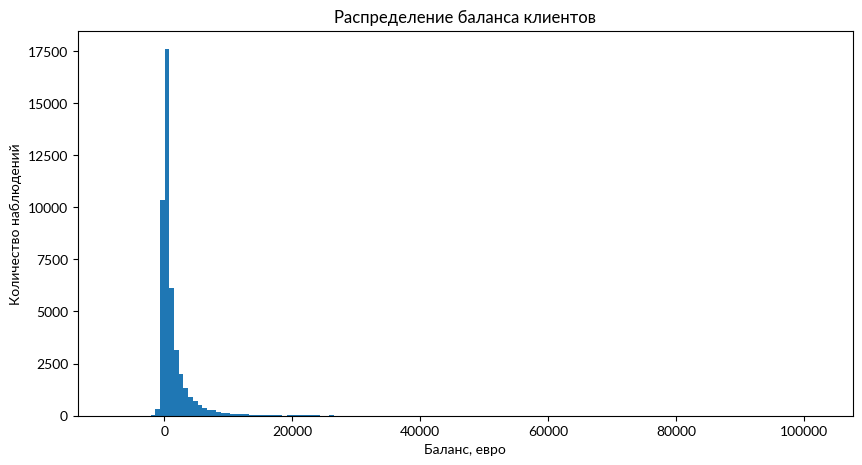

In [ ]:
# Гистограмма распределения баланса клиентов
plt.figure(figsize=(10, 5))

plt.hist(target_marketing['balance'], bins=150)

plt.title('Распределение баланса клиентов')
plt.xlabel('Баланс, евро')
plt.ylabel('Количество наблюдений')
plt.show()

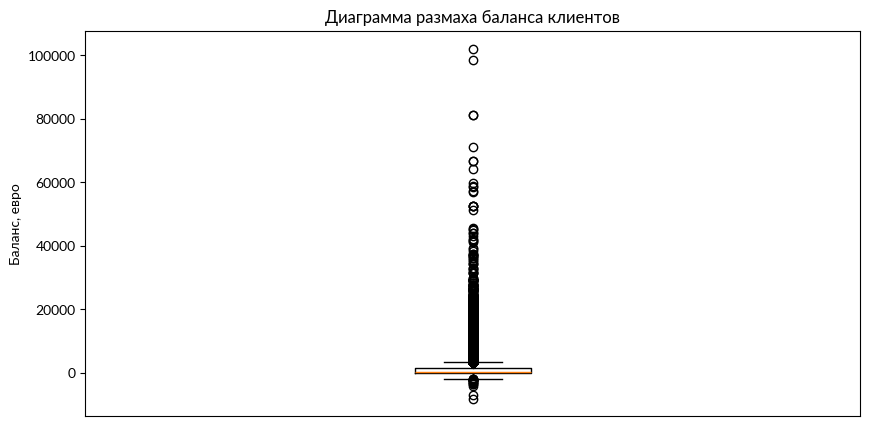

In [ ]:
# Диаграмма размаха баланса клиентов
plt.figure(figsize=(10, 5))

plt.boxplot(target_marketing['balance'])

plt.title('Диаграмма размаха баланса клиентов')
plt.ylabel('Баланс, евро')
plt.xticks([])
plt.show()

In [ ]:
# Границы выбросов и их количество (метод IQR)
q1 = target_marketing['balance'].quantile(0.25)
q3 = target_marketing['balance'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = target_marketing[
    (target_marketing['balance'] < lower) |
    (target_marketing['balance'] > upper)
]

print(f'Нижняя граница: {lower}')
print(f'Верхняя граница: {upper}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {len(outliers) / len(target_marketing) * 100:.2f}%')

Нижняя граница: -1962.0
Верхняя граница: 3462.0
Количество выбросов: 4729
Доля выбросов: 10.46%


• По методу межквартильного размаха выявлено 4 729 выбросов (10,46% наблюдений). Учитывая выраженную правостороннюю асимметрию распределения, экстремальные значения баланса не обязательно являются ошибочными. Удаление таких наблюдений может привести к потере значимой информации о клиентах, поэтому исходные значения `balance` сохранены для дальнейшего анализа.

### **Анализ столбца `duration`**

In [ ]:
# Контакты с нулевой продолжительностью
zero_duration = (target_marketing['duration'] == 0).sum()

print(f'Нулевая продолжительность: {zero_duration} наблюдений')
print(f'Доля: {zero_duration / len(target_marketing) * 100:.2f}%')
target_marketing[target_marketing['duration'] == 0][
    ['duration', 'contact', 'campaign', 'y']
]

Нулевая продолжительность: 3 наблюдений
Доля: 0.01%


,duration,contact,campaign,y
6424,0,unknown,4,no
22937,0,cellular,15,no
36425,0,cellular,2,no


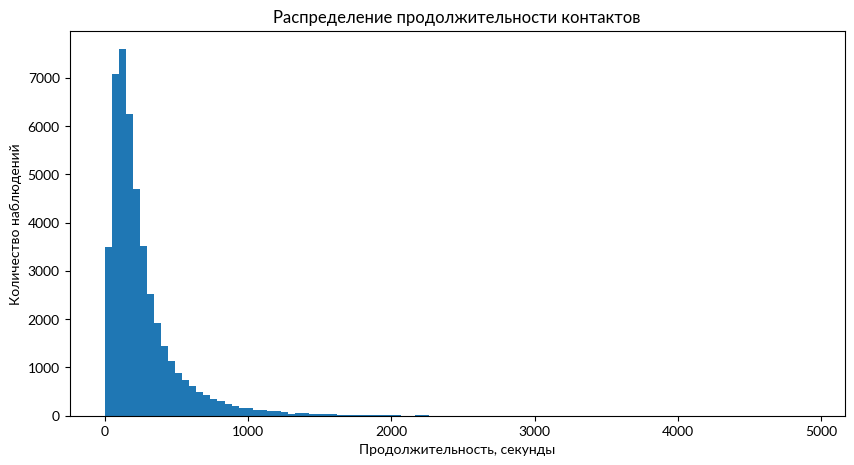

In [ ]:
# Гистограмма распределения продолжительности контактов
plt.figure(figsize=(10, 5))

plt.hist(target_marketing['duration'], bins=100)

plt.title('Распределение продолжительности контактов')
plt.xlabel('Продолжительность, секунды')
plt.ylabel('Количество наблюдений')
plt.show()

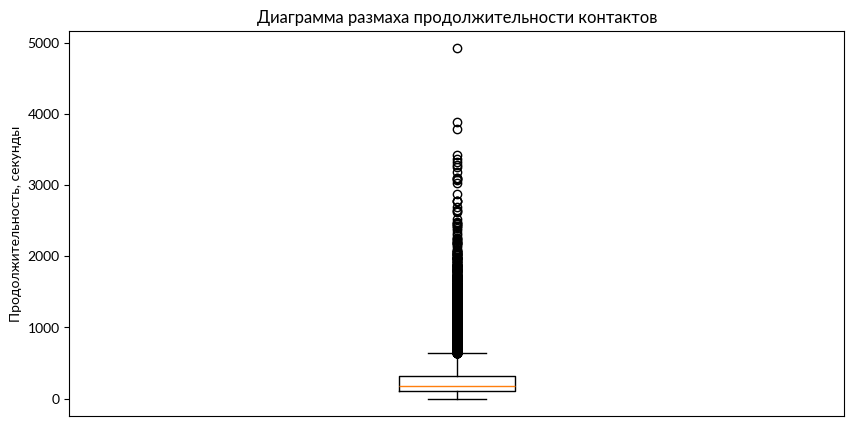

In [ ]:
# Диаграмма размаха продолжительности контактов
plt.figure(figsize=(10, 5))

plt.boxplot(target_marketing['duration'])

plt.title('Диаграмма размаха продолжительности контактов')
plt.ylabel('Продолжительность, секунды')
plt.xticks([])
plt.show()

In [ ]:
# Границы выбросов и их количество (метод IQR)
q1 = target_marketing['duration'].quantile(0.25)
q3 = target_marketing['duration'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = target_marketing[
    (target_marketing['duration'] < lower) |
    (target_marketing['duration'] > upper)
]

print(f'Нижняя граница: {lower}')
print(f'Верхняя граница: {upper}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {len(outliers) / len(target_marketing) * 100:.2f}%')

Нижняя граница: -221.0
Верхняя граница: 643.0
Количество выбросов: 3235
Доля выбросов: 7.16%


• Распределение продолжительности контактов характеризуется выраженной правосторонней асимметрией. Методом IQR выявлено 3 235 выбросов (7,16% наблюдений). Длительные контакты могут отражать реальные особенности взаимодействия с клиентами, поэтому выявленные значения решено сохранить для дальнейшего анализа.

### **Анализ столбца `campaign`**

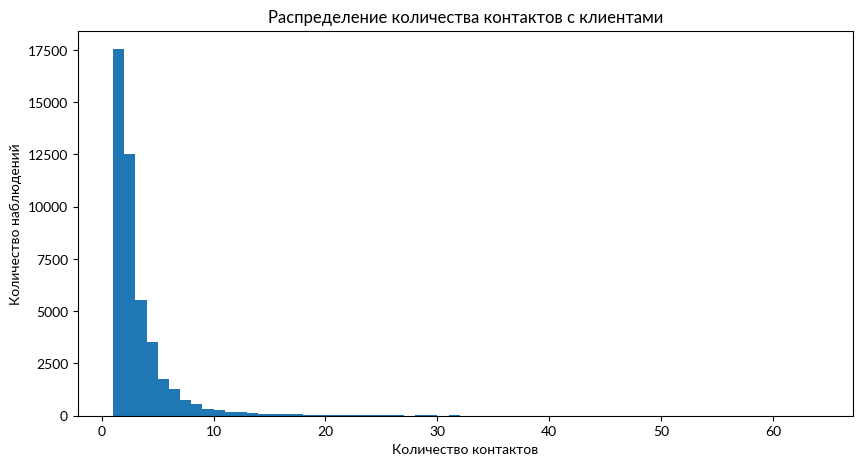

In [ ]:
# Гистограмма распределения количества контактов
plt.figure(figsize=(10, 5))

plt.hist(
    target_marketing['campaign'],
    bins=range(1, 65)
)

plt.title('Распределение количества контактов с клиентами')
plt.xlabel('Количество контактов')
plt.ylabel('Количество наблюдений')
plt.show()

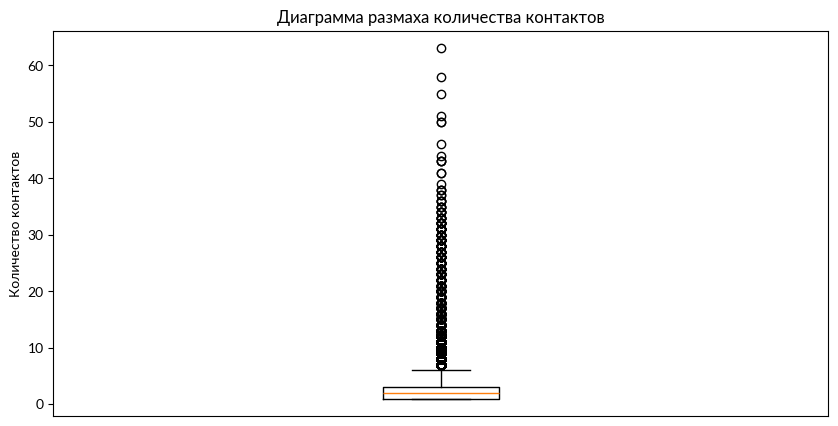

In [ ]:
# Диаграмма размаха количества контактов
plt.figure(figsize=(10, 5))

plt.boxplot(target_marketing['campaign'])

plt.title('Диаграмма размаха количества контактов')
plt.ylabel('Количество контактов')
plt.xticks([])
plt.show()

In [ ]:
# Границы выбросов и их количество (метод IQR)
q1 = target_marketing['campaign'].quantile(0.25)
q3 = target_marketing['campaign'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = target_marketing[
    (target_marketing['campaign'] < lower) |
    (target_marketing['campaign'] > upper)
]

print(f'Нижняя граница: {lower}')
print(f'Верхняя граница: {upper}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {len(outliers) / len(target_marketing) * 100:.2f}%')

Нижняя граница: -2.0
Верхняя граница: 6.0
Количество выбросов: 3064
Доля выбросов: 6.78%


In [ ]:
# Доля клиентов, оформивших вклад, в зависимости от количества контактов
up_to_6_contacts = target_marketing[target_marketing['campaign'] <= 6]
over_6_contacts = target_marketing[target_marketing['campaign'] > 6]

print(f'До 6 контактов: {(up_to_6_contacts["y"] == "yes").mean() * 100:.2f}%')
print(f'Более 6 контактов: {(over_6_contacts["y"] == "yes").mean() * 100:.2f}%')

До 6 контактов: 12.17%
Более 6 контактов: 5.25%


• Распределение признака `campaign` характеризуется выраженной правосторонней асимметрией. Методом IQR выявлено 3 064 выброса (6,78% наблюдений). Доля оформленных вкладов среди клиентов с более чем 6 контактами составляет 5,25% против 12,17% среди остальных клиентов. Учитывая различия в результативности кампании, выявленные наблюдения решено сохранить для дальнейшего анализа.

### **Анализ столбца `pdays`**

In [ ]:
# Количество наблюдений с известным интервалом с предыдущим контактом
# и без него
zero_pdays = (target_marketing['pdays'] == -1).sum()
positive_pdays = (target_marketing['pdays'] != -1).sum()

print(f'Без предыдущих контактов: {zero_pdays}')
print(f'С предыдущими контактами: {positive_pdays}')

Без предыдущих контактов: 36954
С предыдущими контактами: 8257


In [ ]:
# Наблюдения с предыдущими контактами
pdays_contacted = target_marketing[target_marketing['pdays'] != -1]
pdays_contacted['pdays'].describe()

,pdays
count,8257.000000
mean,224.577692
std,115.344035
min,1.000000
25%,133.000000
50%,194.000000
75%,327.000000
max,871.000000


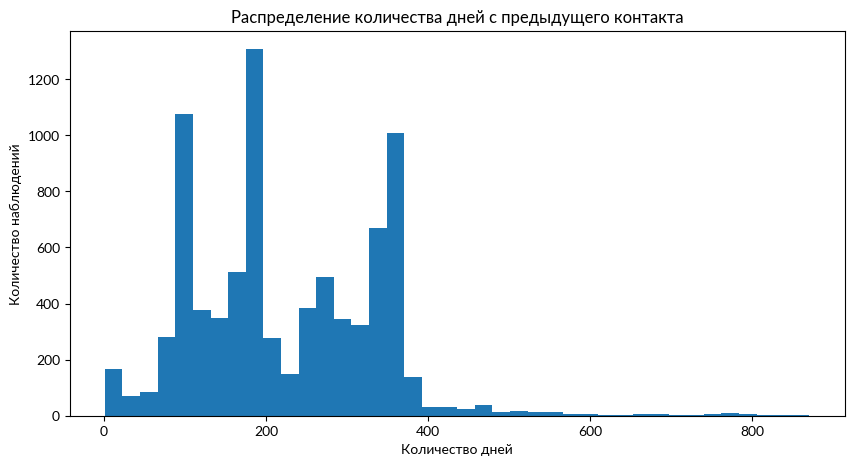

In [ ]:
# Гистограмма распределения количества дней с предыдущего контакта
plt.figure(figsize=(10, 5))

plt.hist(pdays_contacted['pdays'], bins=40)

plt.title('Распределение количества дней с предыдущего контакта')
plt.xlabel('Количество дней')
plt.ylabel('Количество наблюдений')
plt.show()

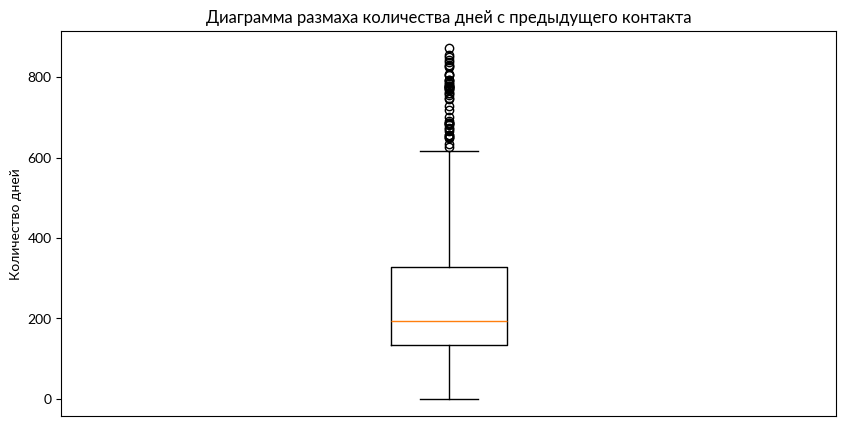

In [ ]:
# Диаграмма размаха количества дней с предыдущего контакта
plt.figure(figsize=(10, 5))

plt.boxplot(pdays_contacted['pdays'])

plt.title('Диаграмма размаха количества дней с предыдущего контакта')
plt.ylabel('Количество дней')
plt.xticks([])
plt.show()

In [ ]:
# Границы выбросов и их количество (метод IQR)
q1 = pdays_contacted['pdays'].quantile(0.25)
q3 = pdays_contacted['pdays'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = pdays_contacted[
    (pdays_contacted['pdays'] < lower) |
    (pdays_contacted['pdays'] > upper)
]

print(f'Нижняя граница: {lower}')
print(f'Верхняя граница: {upper}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {len(outliers) / len(pdays_contacted) * 100:.2f}%')

Нижняя граница: -158.0
Верхняя граница: 618.0
Количество выбросов: 49
Доля выбросов: 0.59%


• При анализе `pdays` значение -1, обозначающее отсутствие предыдущих контактов, было исключено из расчётов. Среди оставшихся 8 257 наблюдений методом IQR выявлено 49 выбросов (0,59%). Поскольку длительные интервалы между контактами могут отражать реальные особенности взаимодействия с клиентами, исходные значения решено сохранить.

### **Анализ столбца `previous`**

In [ ]:
# Количество наблюдений с нулевым и положительным числом
# предыдущих контактов
zero_previous = (target_marketing['previous'] == 0).sum()
positive_previous = (target_marketing['previous'] > 0).sum()

print(f'Без предыдущих контактов: {zero_previous} наблюдений')
print(f'С предыдущими контактами: {positive_previous} наблюдений')

Без предыдущих контактов: 36954 наблюдений
С предыдущими контактами: 8257 наблюдений


In [ ]:
# Наблюдения с предыдущими контактами
previous_contacted = target_marketing[target_marketing['previous'] > 0]
previous_contacted['previous'].describe()

,previous
count,8257.000000
mean,3.177546
std,4.560820
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,275.000000


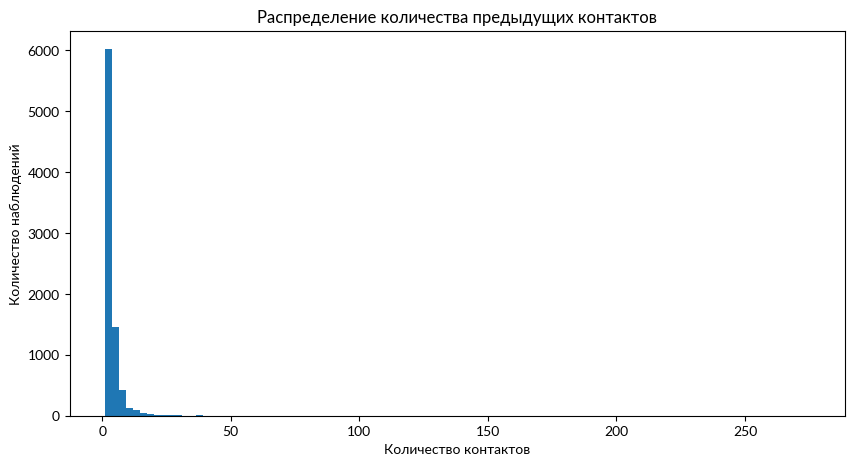

In [ ]:
# Гистограмма распределения количества предыдущих контактов
plt.figure(figsize=(10, 5))

plt.hist(previous_contacted['previous'], bins=100)

plt.title('Распределение количества предыдущих контактов')
plt.xlabel('Количество контактов')
plt.ylabel('Количество наблюдений')
plt.show()

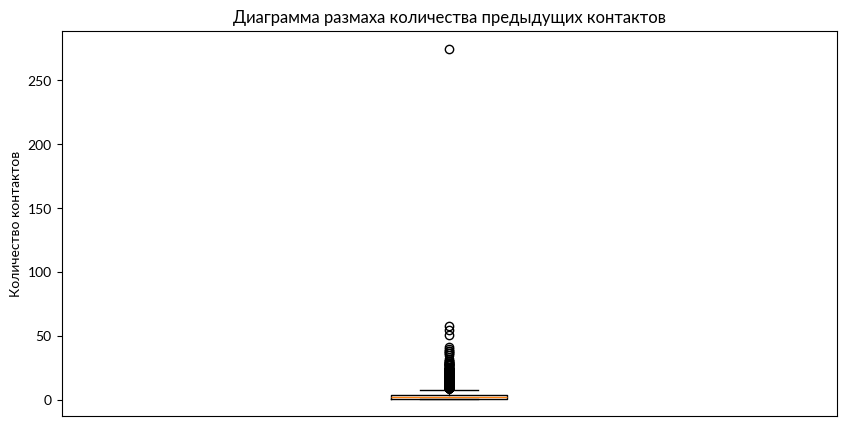

In [ ]:
# Диаграмма размаха количества предыдущих контактов
plt.figure(figsize=(10, 5))

plt.boxplot(previous_contacted['previous'])

plt.title('Диаграмма размаха количества предыдущих контактов')
plt.ylabel('Количество контактов')
plt.xticks([])
plt.show()

In [ ]:
# Границы выбросов и их количество (метод IQR)
q1 = previous_contacted['previous'].quantile(0.25)
q3 = previous_contacted['previous'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = previous_contacted[
    (previous_contacted['previous'] < lower) |
    (previous_contacted['previous'] > upper)
]

print(f'Нижняя граница: {lower}')
print(f'Верхняя граница: {upper}')
print(f'Количество выбросов: {len(outliers)}')
print(f'Доля выбросов: {len(outliers) / len(previous_contacted) * 100:.2f}%')

Нижняя граница: -3.5
Верхняя граница: 8.5
Количество выбросов: 453
Доля выбросов: 5.49%


• При анализе признака `previous` нулевые значения были исключены из расчёта границ выбросов. Среди оставшихся 8 257 наблюдений методом IQR выявлено 453 выброса (5,49%). Максимальное значение составляет 275 контактов и значительно превышает остальные значения признака. Поскольку достоверных оснований считать эти наблюдения ошибочными нет, исходные данные решено сохранить для дальнейшего анализа.

• В ходе анализа числовых признаков были выявлены статистические выбросы, однако оснований считать их ошибочными не обнаружено. Поскольку исключение экстремальных значений может привести к потере значимой информации о клиентах, исходные наблюдения сохранены для дальнейшего анализа. Необходимость дополнительной обработки отдельных признаков будет оцениваться на этапе построения моделей.

## *Добавление новых признаков*

### *season (сезон последнего контакта)*


In [ ]:
seasons = {
    'dec': 'winter', 'jan': 'winter', 'feb': 'winter',
    'mar': 'spring', 'apr': 'spring', 'may': 'spring',
    'jun': 'summer', 'jul': 'summer', 'aug': 'summer',
    'sep': 'autumn', 'oct': 'autumn', 'nov': 'autumn'
}

target_marketing['season'] = target_marketing['month'].map(seasons)
target_marketing['season'].isna().sum()

np.int64(0)

• На основе столбца `month` создан новый категориальный признак `season`, определяющий сезон последнего контакта с клиентом. Он позволит сравнить конверсию маркетинговых кампаний в разные сезоны года и выявить возможные сезонные различия.

### *credit_commitment* (наличие кредитных обязательств)

In [ ]:
target_marketing['credit_commitment'] = np.where(
    (target_marketing['loan'] == 'yes') |
    (target_marketing['housing'] == 'yes'),
    1,
    0
)
target_marketing['credit_commitment'].value_counts()

,count
credit_commitment,
1,28007
0,17204


• На основе столбцов `loan` и `housing` создан новый бинарный признак `credit_commitment`, отражающий наличие у клиента жилищного или потребительского кредита. Признак принимает значение 1, если у клиента есть хотя бы один из указанных видов кредита, и 0 — если оба отсутствуют. Это позволит сравнить конверсию среди двух групп клиентов.

### *has_previous_contact* (наличие предыдущих контактов с клиентом)

In [ ]:
target_marketing['has_previous_contact'] = (
    target_marketing['pdays'] > 0
).astype(int)

target_marketing['has_previous_contact'].value_counts()

,count
has_previous_contact,
0,36954
1,8257


• На основе столбца `previous` создан бинарный признак `has_previous_contact`, отражающий наличие предыдущих контактов с клиентом. Значение 1 соответствует наличию хотя бы одного контакта до текущей маркетинговой кампании, значение 0 — их отсутствию. Признак позволит сравнить конверсию клиентов с историей предыдущих взаимодействий с банком и без нее.

### *contact_recency_group* (давность предыдущего контакта с клиентом)

In [ ]:
def contact_recency(pdays):
  if pdays == -1:
    return 'no_previous_contact'
  elif pdays <= 90:
    return '1-90_days'
  elif pdays <= 180:
    return '91-180_days'
  elif pdays <= 365:
    return '181-365_days'
  else:
    return 'over_365_days'

In [ ]:
target_marketing['contact_recency_group'] = target_marketing['pdays'].apply(
    contact_recency
)
target_marketing['contact_recency_group'].value_counts()

,count
contact_recency_group,
no_previous_contact,36954
181-365_days,4416
91-180_days,2480
1-90_days,718
over_365_days,643


• На основе столбца `pdays` создан категориальный признак `contact_recency_group`, разделяющий клиентов на группы по количеству дней с момента предыдущего контакта. Отдельно выделены клиенты без предыдущих контактов. Признак позволит исследовать связь между давностью взаимодействия с клиентом и конверсией в оформление вклада.

### *previous_success* (успешность предыдущей маркетинговой кампании)

In [ ]:
target_marketing['previous_success'] = (
    target_marketing['poutcome'] == 'success'
).astype(int)

target_marketing['previous_success'].value_counts()

,count
previous_success,
0,43700
1,1511


• На основе столбца `poutcome` создан бинарный признак `previous_success`, отражающий наличие успешного результата предыдущей маркетинговой кампании. Значение 1 соответствует успешному результату, 0 — отсутствию зафиксированного успеха. Признак позволит сравнить конверсию клиентов с положительным опытом предыдущих кампаний и остальных клиентов.

### *contact_intensity* (интенсивность контактов в рамках текущей маркетинговой кампании)

In [ ]:
def contact_intensity(campaign):
  if campaign == 1:
    return '1_contact'
  elif campaign <= 3:
    return '2-3_contacts'
  elif campaign <= 6:
    return '4-6_contacts'
  else:
    return 'over_6_contacts'

In [ ]:
target_marketing['contact_intensity'] = target_marketing['campaign'].apply(
    contact_intensity
)
target_marketing['contact_intensity'].value_counts()

,count
contact_intensity,
2-3_contacts,18026
1_contact,17544
4-6_contacts,6577
over_6_contacts,3064


• На основе столбца `campaign` создан категориальный признак `contact_intensity`, разделяющий клиентов на четыре группы в зависимости от количества контактов в рамках текущей маркетинговой кампании. Признак позволит исследовать различия в конверсии между группами клиентов с разной интенсивностью взаимодействия с банком.

## *Анализ факторов, связанных с результативностью маркетинговых кампаний*

### **Анализ целевой переменной и общей конверсии**

• Для оценки результативности маркетинговых кампаний рассмотрим распределение целевой переменной `y`, отражающей факт оформления банковского вклада. Рассчитаем общую конверсию как долю клиентов, оформивших вклад, среди всех наблюдений.

In [ ]:
# Общая конверсия в оформление вклада
conversion_rate = (target_marketing['y'] == 'yes').mean() * 100

print(f'Общая конверсия: {conversion_rate:.2f}%')

Общая конверсия: 11.70%


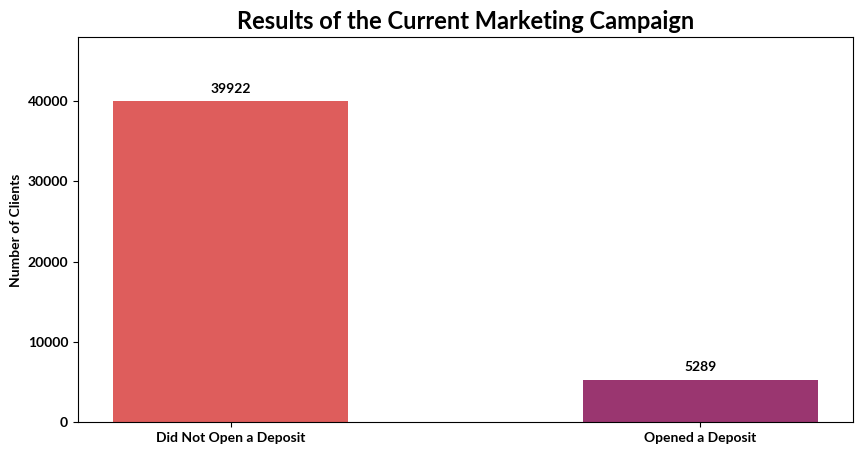

In [ ]:
# Диаграмма распределения целевой переменной
counts = target_marketing['y'].value_counts()

plt.figure(figsize=(10, 5))

bars = plt.bar(
    ['Did Not Open a Deposit', 'Opened a Deposit'],
    [counts['no'], counts['yes']],
    color=sns.color_palette('flare', 2),
    width=0.5
)

plt.title('Results of the Current Marketing Campaign', fontsize=17, fontweight='bold')
plt.ylabel('Number of Clients', fontweight='bold')

plt.bar_label(bars, padding=5, fontweight='bold')
plt.ylim(0, counts.max() * 1.2)

plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')

plt.show()

• Из 45 211 наблюдений в 5 289 случаях (11,70%) клиенты оформили банковский вклад, в 39 922 случаях (88,30%) — не оформили. Распределение целевой переменной характеризуется выраженным дисбалансом классов, что необходимо учитывать при дальнейшем построении прогнозной модели.

### **Анализ характеристик клиентов**

In [ ]:
# Сравним возраст клиентов в зависимости от оформления вклада
target_marketing.groupby('y')['age'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
y,,,
no,39922,40.84,39.0
yes,5289,41.67,38.0


In [ ]:
def age_group(age):
  if age < 30:
    return '18-29'
  elif age < 40:
    return '30-39'
  elif age < 50:
    return '40-49'
  elif age < 60:
    return '50-59'
  elif age < 70:
    return '60-69'
  elif age < 80:
    return '70-79'
  else:
    return '80+'

target_marketing['age_group'] = target_marketing['age'].apply(age_group)

In [ ]:
age_conversion = target_marketing.groupby('age_group')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

age_conversion

,total,conversion
age_group,,
18-29,5273,17.60
30-39,18089,10.58
40-49,11655,9.12
50-59,8410,9.33
60-69,1230,29.67
70-79,424,42.45
80+,130,42.31


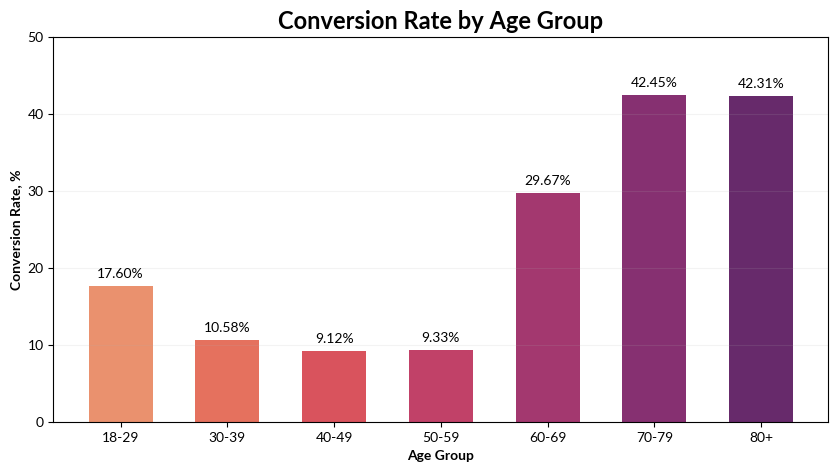

In [ ]:
# Столбчатая диаграмма конверсии по возрастным группам
plt.figure(figsize=(10, 5))

bars = plt.bar(
    age_conversion.index,
    age_conversion['conversion'],
    color=sns.color_palette('flare', 7),
    width=0.6
)

plt.title('Conversion Rate by Age Group', fontsize=17, fontweight='bold')
plt.xlabel('Age Group', fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 50)
plt.grid(axis='y', alpha=0.15)

plt.show()

• Конверсия в оформление банковского вклада заметно различается между возрастными группами. Наиболее высокие значения наблюдаются среди клиентов 70-79 лет (42,45%) и старше 80 лет (42,31%), тогда как среди клиентов 40-59 лет конверсия не превышает 10%. Полученные результаты указывают на нелинейную связь возраста с конверсией. При этом необходимо учитывать различия в численности возрастных групп.

In [ ]:
# Конверсия по роду занятий клиентов
job_conversion = target_marketing.groupby('job')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

job_conversion = job_conversion.sort_values(by='conversion', ascending=False)
job_conversion

,total,conversion
job,,
student,938,28.68
retired,2264,22.79
unemployed,1303,15.50
management,9458,13.76
admin.,5171,12.20
self-employed,1579,11.84
unknown,288,11.81
technician,7597,11.06
services,4154,8.88


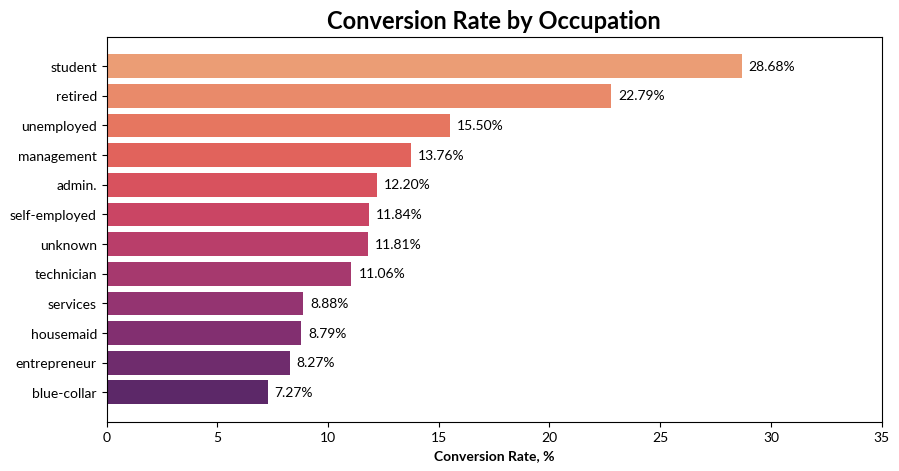

In [ ]:
# Диаграмма конверсии по роду занятий клиентов
plt.figure(figsize=(10, 5))

bars = plt.barh(
    job_conversion.index,
    job_conversion['conversion'],
    color=sns.color_palette('flare', len(job_conversion))
)

plt.gca().invert_yaxis()

plt.title('Conversion Rate by Occupation', fontsize=17, fontweight='bold')
plt.xlabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.xlim(0, 35)

plt.show()

• Конверсия в оформление банковского вклада различается в зависимости от рода занятий клиентов. Наиболее высокие показатели наблюдаются среди студентов (28,68%) и пенсионеров (22,79%), наиболее низкий - среди рабочих (7,27%). Высокая конверсия среди пенсионеров согласуется с ранее выявленными различиями между возрастными группами.

In [ ]:
# Конверсия по семейному положению клиентов
marital_conversion = target_marketing.groupby('marital')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

marital_conversion = marital_conversion.sort_values('conversion', ascending=False)
marital_conversion

,total,conversion
marital,,
single,12790,14.95
divorced,5207,11.95
married,27214,10.12


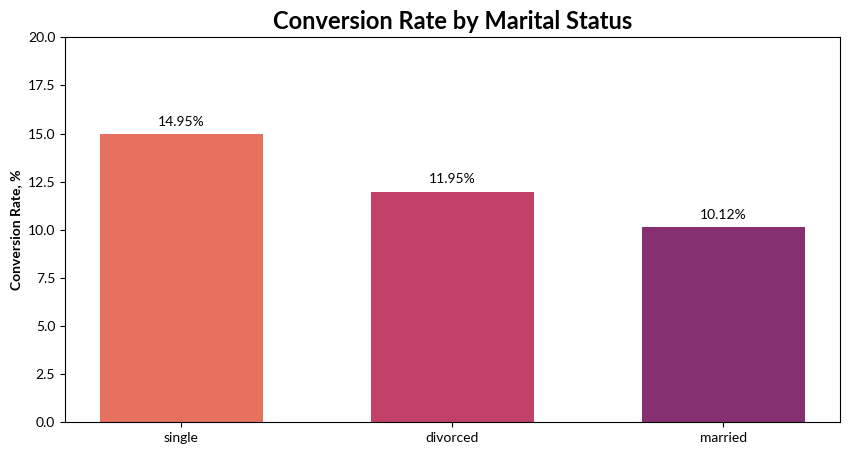

In [ ]:
# Диаграмма конверсии по семейному положению клиентов
plt.figure(figsize=(10, 5))

bars = plt.bar(
    marital_conversion.index,
    marital_conversion['conversion'],
    color=sns.color_palette('flare', 3),
    width=0.6
)

plt.title('Conversion Rate by Marital Status', fontsize=17, fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 20)

plt.show()

• Конверсия в оформление банковского вклада различается в зависимости от семейного положения клиентов. Наиболее высокая конверсия наблюдается среди клиентов, не состоящих в браке (14,95%), наиболее низкая - среди состоящих в браке (10,12%). При этом выявленные различия могут быть связаны с возрастными характеристиками клиентов.

In [ ]:
# Конверсия по уровню образования клиентов
education_conversion = target_marketing.groupby('education')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

education_conversion = education_conversion.sort_values(
    'conversion', ascending=False
)
education_conversion

,total,conversion
education,,
tertiary,13301,15.01
unknown,1857,13.57
secondary,23202,10.56
primary,6851,8.63


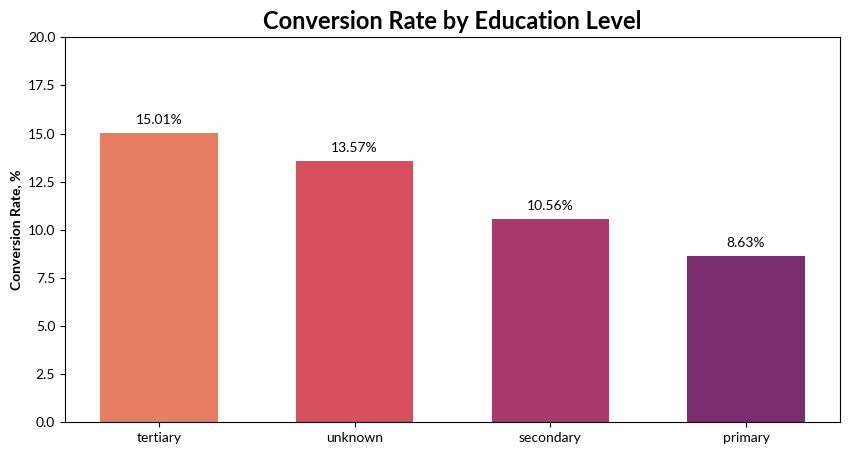

In [ ]:
# Диаграмма конверсии по уровню образования клиентов
plt.figure(figsize=(10, 5))

bars = plt.bar(
    education_conversion.index,
    education_conversion['conversion'],
    color=sns.color_palette('flare', 4),
    width=0.6
)

plt.title('Conversion Rate by Education Level', fontsize=17, fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 20)

plt.show()

• Конверсия в оформление банковского вклада различается в зависимости от уровня образования клиентов. Наиболее высокая конверсия наблюдается среди клиентов с высшим образованием (15,01%), наиболее низкая - с начальным (8,63%). Среди клиентов со средним образованием конверсия составляет 10,56%.

In [ ]:
# Сравниваем баланс клиентов в зависимости от оформления вклада
target_marketing.groupby('y')['balance'].agg(
    ['count', 'mean', 'median']
).round(2)

,count,mean,median
y,,,
no,39922,1303.71,417.0
yes,5289,1804.27,733.0


In [ ]:
def balance_group(balance):
    if balance < 0:
        return 'Negative'
    elif balance == 0:
        return 'Zero'
    elif balance <= 500:
        return '1-500'
    elif balance <= 1500:
        return '501-1500'
    elif balance <= 5000:
        return '1501-5000'
    else:
        return 'Over 5000'

target_marketing['balance_group'] = target_marketing['balance'].apply(balance_group)

In [ ]:
# Конверсия по группам баланса
balance_conversion = target_marketing.groupby('balance_group')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

balance_conversion

,total,conversion
balance_group,,
1-500,16385,10.25
1501-5000,8050,16.61
501-1500,10651,12.48
Negative,3766,5.58
Over 5000,2845,15.50
Zero,3514,8.31


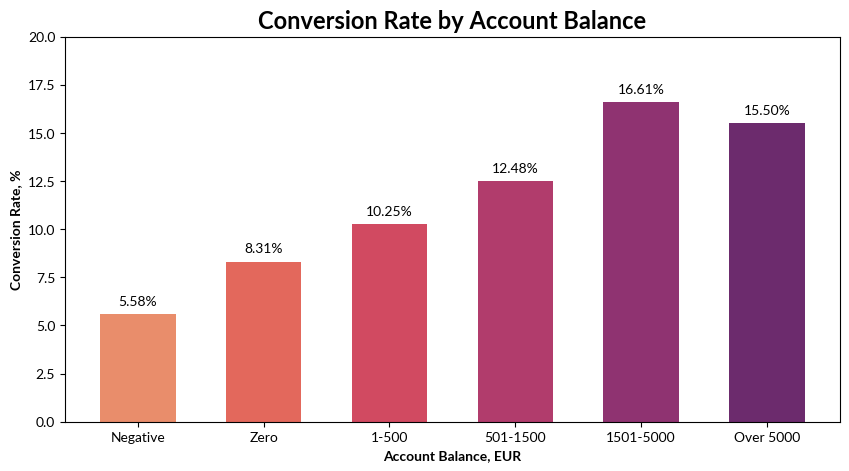

In [ ]:
# Диаграмма конверсии по величине баланса
balance_order = ['Negative', 'Zero', '1-500', '501-1500', '1501-5000', 'Over 5000']
balance_conversion = balance_conversion.reindex(balance_order)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    balance_conversion.index,
    balance_conversion['conversion'],
    color=sns.color_palette('flare', 6),
    width=0.6
)

plt.title('Conversion Rate by Account Balance', fontsize=17, fontweight='bold')
plt.xlabel('Account Balance, EUR', fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 20)

plt.show()

• Конверсия в оформление банковского вклада в целом возрастает с увеличением баланса клиентов. Наиболее низкая конверсия наблюдается среди клиентов с отрицательным балансом (5,58%), наиболее высокая - при балансе от 1 501 до 5 000 евро (16,61%). Среди клиентов с балансом свыше 5 000 евро показатель немного ниже (15,50%). Результаты указывают на положительную, но не строго монотонную связь между величиной баланса и конверсией.

### **Анализ кредитных обязательств и проверка гипотезы H1**

**Исследовательская гипотеза H1:** конверсия в оформление банковского вклада различается между клиентами с кредитными обязательствами и без них.

**H₀:** конверсия одинакова в обеих группах.

**H₁:** конверсия различается между группами.

In [ ]:
# Конверсия в зависимости от наличия кредитных обязательств
credit_conversion = target_marketing.groupby('credit_commitment')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

credit_conversion

,total,conversion
credit_commitment,,
0,17204,18.22
1,28007,7.69


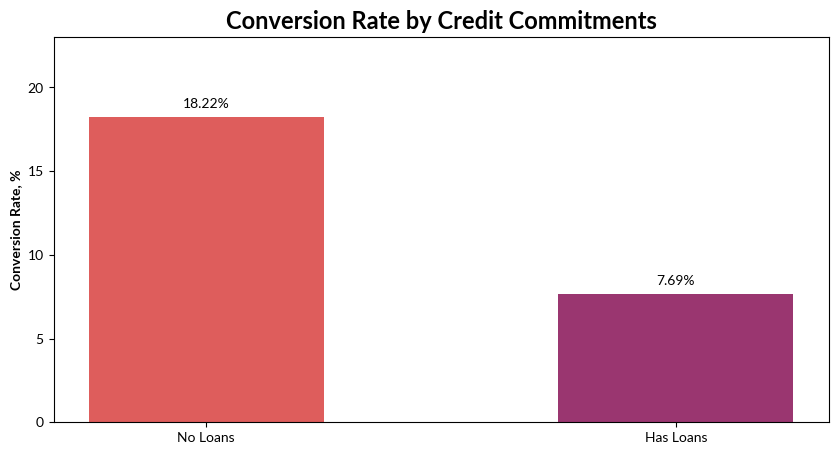

In [ ]:
# Диаграмма конверсии по наличию кредитных обязательств
plt.figure(figsize=(10, 5))

bars = plt.bar(
    ['No Loans', 'Has Loans'],
    credit_conversion['conversion'],
    color=sns.color_palette('flare', 2),
    width=0.5
)

plt.title('Conversion Rate by Credit Commitments', fontsize=17, fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 23)

plt.show()

In [ ]:
# Проверка гипотезы
from scipy.stats import chi2_contingency

credit_table = pd.crosstab(
    target_marketing['credit_commitment'],
    target_marketing['y']
)

chi2, p_value, dof, expected = chi2_contingency(
    credit_table, correction=False
)

print(f'Хи-квадрат: {chi2:.2f}')
print(f'p-value: {p_value:.4e}')
print(f'Минимальная ожидаемая частота: {expected.min():.2f}')

Хи-квадрат: 1144.30
p-value: 7.7670e-251
Минимальная ожидаемая частота: 2012.61


• Конверсия среди клиентов без жилищного и потребительского кредитов составляет 18,22%, что на 10,53 п. п. выше, чем среди клиентов с кредитными обязательствами (7,69%). Критерий хи-квадрат Пирсона подтвердил статистически значимую связь между наличием рассматриваемых кредитов и оформлением банковского вклада (χ² = 1144,30; p < 0,001). **Гипотеза H1 получила статистическое подтверждение.** При этом выявленная связь не доказывает причинно-следственную зависимость и может быть обусловлена в том числе другими характеристиками клиентов.

### **Анализ результатов предыдущих маркетинговых кампаний и проверка гипотезы H2**

**Исследовательская гипотеза H2:** клиенты с успешным результатом предыдущей маркетинговой кампании имеют более высокую конверсию в оформление вклада в текущей кампании.

**H₀:** конверсия в оформление банковского вклада не различается между клиентами с успешным результатом предыдущей маркетинговой кампании и клиентами, у которых такой результат не зафиксирован.

**H₁:** конверсия в оформление банковского вклада выше среди клиентов с успешным результатом предыдущей маркетинговой кампании.

In [ ]:
# Оставляем клиентов, с которыми ранее уже связывались
contacted_clients = target_marketing[target_marketing['previous'] > 0]

# Конверсия в зависимости от успешности предыдущей кампании
contacted_conversion = contacted_clients.groupby('previous_success')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

contacted_conversion

,total,conversion
previous_success,,
0,6746,13.74
1,1511,64.73


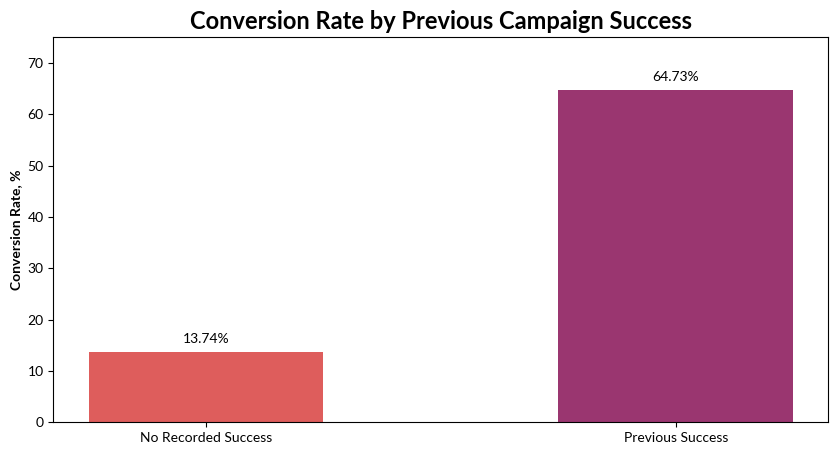

In [ ]:
# Диаграмма конверсии по результатам предыдущих кампаний
plt.figure(figsize=(10, 5))

bars = plt.bar(
    ['No Recorded Success', 'Previous Success'],
    contacted_conversion['conversion'],
    color=sns.color_palette('flare', 2),
    width=0.5
)

plt.title('Conversion Rate by Previous Campaign Success', fontsize=17, fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 75)

plt.show()

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# Выделяем две группы клиентов
success = contacted_clients[contacted_clients['previous_success'] == 1]['y']
no_success = contacted_clients[contacted_clients['previous_success'] == 0]['y']

count = [(success == 'yes').sum(), (no_success == 'yes').sum()]
nobs = [len(success), len(no_success)]

Z-статистика: 42.52
p-value: 0.0000e+00


In [ ]:
# Односторонний Z-тест для двух пропорций
z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

print(f'Z-статистика: {z_stat:.2f}')
print(f'p-value: {p_value:.4e}')

Z-статистика: 42.52
p-value: 0.0000e+00


• Среди клиентов с историей предыдущих контактов конверсия при наличии успешного результата прошлой маркетинговой кампании составляет 64,73%, тогда как среди клиентов без зафиксированного успеха - 13,74%. Разница достигает 50,99 п. п. Односторонний Z-тест для двух пропорций подтвердил статистическую значимость различий (Z = 42,52; p < 0,001). **Гипотеза H2 получила статистическое подтверждение:** клиенты с успешным результатом предыдущей кампании значительно чаще оформляют вклад в текущей кампании. При этом выявленная связь не свидетельствует о причинно-следственном влиянии предыдущей кампании на решение клиента.

### **Анализ давности предыдущего контакта и проверка гипотезы H3**

**Исследовательская гипотеза H3:** конверсия в оформление банковского вклада различается в зависимости от времени, прошедшего с момента предыдущего контакта с клиентом.

**H₀:** конверсия в оформление банковского вклада не различается между группами клиентов с разной давностью предыдущего контакта.

**H₁**: конверсия в оформление банковского вклада различается между группами клиентов с разной давностью предыдущего контакта.

In [ ]:
# Клиенты с известной давностью предыдущего контакта
recency_clients = target_marketing[target_marketing['pdays'] >= 0]

# Конверсия по давности предыдущего контакта
recency_conversion = recency_clients.groupby('contact_recency_group')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

recency_order = ['1-90_days', '91-180_days', '181-365_days', 'over_365_days']
recency_conversion = recency_conversion.reindex(recency_order)

recency_conversion

,total,conversion
contact_recency_group,,
1-90_days,718,34.96
91-180_days,2480,27.42
181-365_days,4416,17.80
over_365_days,643,29.24


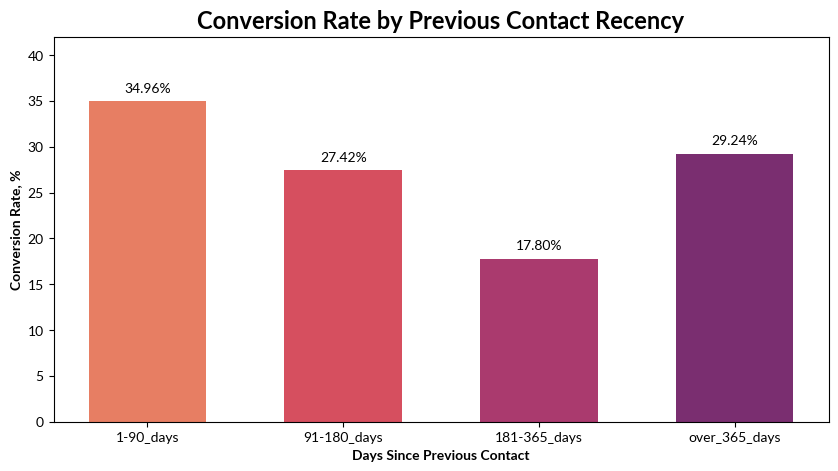

In [ ]:
# Диаграмма конверсии по давности предыдущего контакта
plt.figure(figsize=(10, 5))

bars = plt.bar(
    recency_conversion.index,
    recency_conversion['conversion'],
    color=sns.color_palette('flare', 4),
    width=0.6
)

plt.title('Conversion Rate by Previous Contact Recency', fontsize=17, fontweight='bold')
plt.xlabel('Days Since Previous Contact', fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 42)

plt.show()

In [ ]:
# Проверка гипотезы H3
recency_table = pd.crosstab(
    recency_clients['contact_recency_group'],
    recency_clients['y']
)

chi2, p_value, dof, expected = chi2_contingency(
    recency_table, correction=False
)

print(f'Хи-квадрат: {chi2:.2f}')
print(f'p-value: {p_value:.4e}')
print(f'Минимальная ожидаемая частота: {expected.min():.2f}')

Хи-квадрат: 166.52
p-value: 7.1786e-36
Минимальная ожидаемая частота: 148.35


• Конверсия в оформление банковского вклада различается в зависимости от давности предыдущего контакта с клиентом. Наибольшая конверсия наблюдается при давности контакта до 90 дней (34,96%), наименьшая - от 181 до 365 дней (17,80%). При давности более 365 дней конверсия вновь возрастает до 29,24%, что указывает на немонотонный характер выявленной зависимости. Критерий хи-квадрат Пирсона подтвердил наличие статистически значимой связи между давностью предыдущего контакта и оформлением вклада (χ² = 166,52; p < 0,001). **Гипотеза H3 получила статистическое подтверждение.**

### **Анализ интенсивности контактов и проверка гипотезы H4**

**Исследовательская гипотеза H4:** конверсия в оформление банковского вклада различается в зависимости от количества контактов с клиентом в рамках текущей маркетинговой кампании.

**H₀:** конверсия в оформление банковского вклада одинакова во всех группах клиентов с разным количеством контактов.

**H₁:** конверсия в оформление банковского вклада различается хотя бы между некоторыми группами клиентов.

In [ ]:
# Конверсия в зависимости от количества контактов в текущей кампании
intensity_conversion = target_marketing.groupby('contact_intensity')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

intensity_conversion

,total,conversion
contact_intensity,,
1_contact,17544,14.60
2-3_contacts,18026,11.20
4-6_contacts,6577,8.33
over_6_contacts,3064,5.25


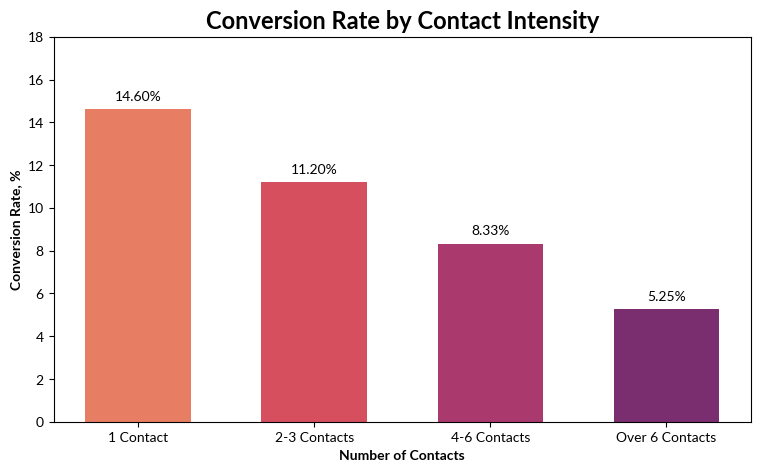

In [ ]:
# Диаграмма конверсии по количеству контактов
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ['1 Contact', '2-3 Contacts', '4-6 Contacts', 'Over 6 Contacts'],
    intensity_conversion['conversion'],
    color=sns.color_palette('flare', 4),
    width=0.6
)

plt.title('Conversion Rate by Contact Intensity', fontsize=17, fontweight='bold')
plt.xlabel('Number of Contacts', fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 18)

plt.show()

In [ ]:
# Проверка гипотезы H4
intensity_table = pd.crosstab(
    target_marketing['contact_intensity'],
    target_marketing['y']
)

chi2, p_value, dof, expected = chi2_contingency(
    intensity_table, correction=False
)

print(f'Хи-квадрат: {chi2:.2f}')
print(f'p-value: {p_value:.4e}')
print(f'Минимальная ожидаемая частота: {expected.min():.2f}')

Хи-квадрат: 342.39
p-value: 6.6208e-74
Минимальная ожидаемая частота: 358.44


• Конверсия в оформление банковского вклада последовательно снижается по мере увеличения количества контактов с клиентом в рамках текущей маркетинговой кампании. Наибольшая конверсия наблюдается среди клиентов с одним контактом (14,60%), наименьшая - среди клиентов с более чем шестью контактами (5,25%). Разница составляет 9,35 п. п. Критерий хи-квадрат Пирсона подтвердил наличие статистически значимой связи между интенсивностью контактов и оформлением вклада (χ² = 342,39; p < 0,001). **Гипотеза H4 получила статистическое подтверждение.**

### **Анализ сезонности маркетинговых кампаний и проверка гипотезы H5**

**Исследовательская гипотеза H5:** конверсия в оформление банковского вклада различается в зависимости от сезона проведения маркетинговой кампании.

**H₀:** конверсия в оформление банковского вклада одинакова во все сезоны.

**H₁:** конверсия в оформление банковского вклада различается хотя бы между некоторыми сезонами.

In [ ]:
# Конверсия в зависимости от сезона проведения кампании
season_conversion = target_marketing.groupby('season')['y'].agg(
    total='count',
    conversion=lambda x: (x == 'yes').mean() * 100
).round(2)

season_order = ['winter', 'spring', 'summer', 'autumn']
season_conversion = season_conversion.reindex(season_order)

season_conversion

,total,conversion
season,,
winter,4266,16.01
spring,17175,10.19
summer,18483,10.07
autumn,5287,18.82


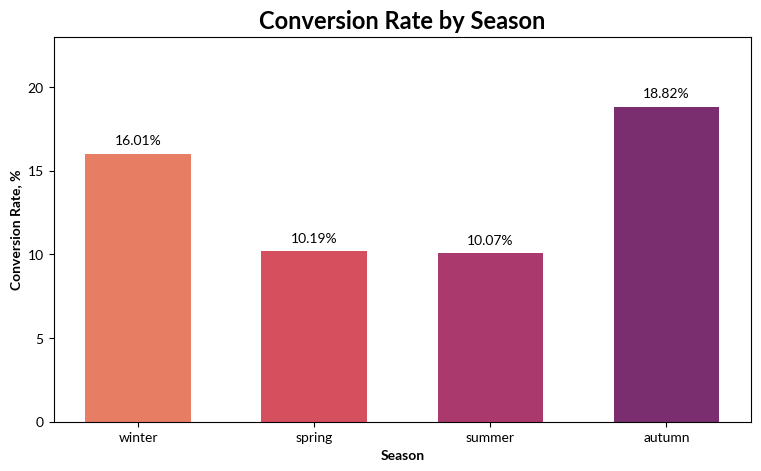

In [ ]:
# Диаграмма конверсии по сезонам
plt.figure(figsize=(9, 5))

bars = plt.bar(
    season_conversion.index,
    season_conversion['conversion'],
    color=sns.color_palette('flare', 4),
    width=0.6
)

plt.title('Conversion Rate by Season', fontsize=17, fontweight='bold')
plt.xlabel('Season', fontweight='bold')
plt.ylabel('Conversion Rate, %', fontweight='bold')

plt.bar_label(bars, fmt='%.2f%%', padding=5)
plt.ylim(0, 23)

plt.show()

In [ ]:
# Проверка гипотезы H5
season_table = pd.crosstab(
    target_marketing['season'],
    target_marketing['y']
)

chi2, p_value, dof, expected = chi2_contingency(
    season_table, correction=False
)

print(f'Хи-квадрат: {chi2:.2f}')
print(f'p-value: {p_value:.4e}')
print(f'Минимальная ожидаемая частота: {expected.min():.2f}')

Хи-квадрат: 421.73
p-value: 4.3432e-91
Минимальная ожидаемая частота: 499.06


• Конверсия в оформление банковского вклада различается в зависимости от сезона проведения маркетинговой кампании. Наиболее высокая конверсия наблюдается осенью (18,82%) и зимой (16,01%), тогда как весной (10,19%) и летом (10,07%) показатели существенно ниже. Разница между максимальной и минимальной конверсией составляет 8,75 п. п. Критерий хи-квадрат Пирсона подтвердил наличие статистически значимой связи между сезоном проведения кампании и оформлением вклада (χ² = 421,73; p < 0,001). **Гипотеза H5 получила статистическое подтверждение.**

## ***Прогнозирование вероятности оформления банковского вклада***

In [ ]:
# Признаки для прогнозирования
features = [
    'age', 'job', 'marital', 'education',
    'default', 'balance', 'housing', 'loan',
    'previous', 'pdays', 'poutcome'
]

X = target_marketing[features].copy()

# Преобразуем целевую переменную в числовой формат
y = (target_marketing['y'] == 'yes').astype(int)

print('Размер X:', X.shape)
print('Размер y:', y.shape)

Размер X: (45211, 11)
Размер y: (45211,)


### *Подготовка данных для моделирования*

In [ ]:
# Разделяем данные на обучающую и тестовую выборки
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (36168, 11)
Тестовая выборка: (9043, 11)


In [ ]:
# Кодируем категориальные признаки
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print('Обучающая выборка:', X_train_encoded.shape)
print('Тестовая выборка:', X_test_encoded.shape)

Обучающая выборка: (36168, 33)
Тестовая выборка: (9043, 33)


In [ ]:
# Стандартизируем числовые признаки
from sklearn.preprocessing import StandardScaler

numeric_features = ['age', 'balance', 'previous', 'pdays']

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

scaler = StandardScaler()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

X_test_scaled[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

In [ ]:
# Проверка стандартизироанных числовых признаков
X_train_scaled[numeric_features].agg(['mean', 'std']).round(2)

,age,balance,previous,pdays
mean,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


### *Построение модели логистической регрессии*

In [ ]:
# Обучаем модель на обучающей выборке
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = log_model.predict(X_test_scaled)

print('Прогнозы:', y_pred[:10])
print('Фактические значения:', y_test.iloc[:10].values)

Прогнозы: [0 0 0 0 0 0 0 1 0 0]
Фактические значения: [0 0 0 0 0 0 0 1 0 0]


### *Оценка качества логистической регрессии*

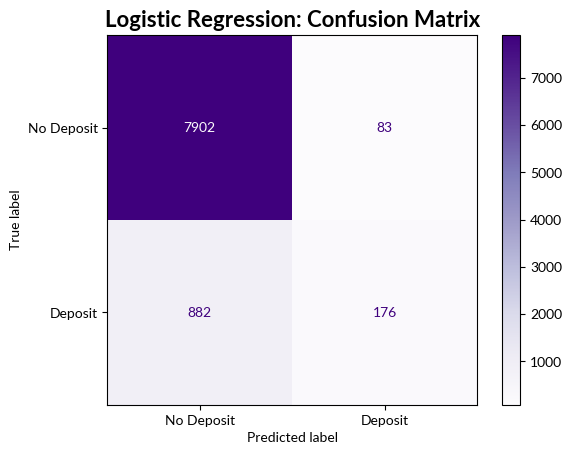

In [ ]:
# Матрица ошибок
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Deposit', 'Deposit']
).plot(cmap='Purples')

plt.title('Logistic Regression: Confusion Matrix', fontsize=16, fontweight='bold')
plt.show()

In [ ]:
# Оценка качества логистической регрессии
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Deposit', 'Deposit']
))

              precision    recall  f1-score   support

  No Deposit       0.90      0.99      0.94      7985
     Deposit       0.68      0.17      0.27      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.58      0.60      9043
weighted avg       0.87      0.89      0.86      9043



In [ ]:
# ROC-AUC
from sklearn.metrics import roc_auc_score

y_proba = log_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')

ROC-AUC: 0.7201


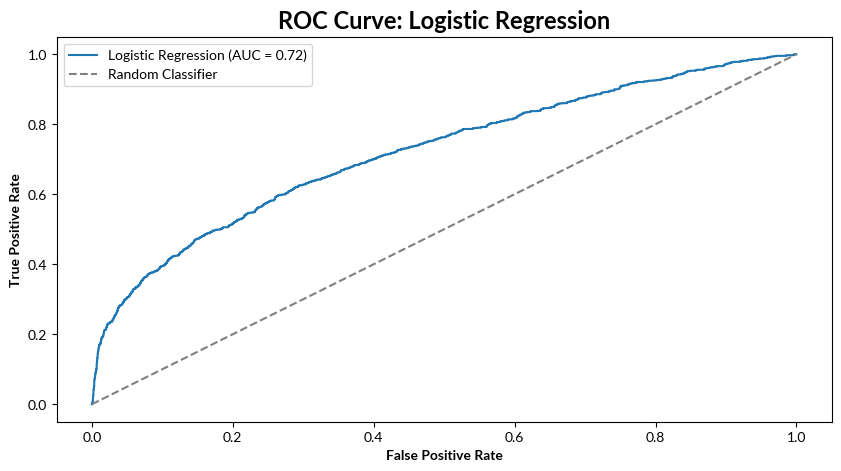

In [ ]:
# ROC-кривая
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 5))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random Classifier')

plt.title('ROC Curve: Logistic Regression', fontsize=17, fontweight='bold')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.legend()

plt.show()

In [ ]:
# Выделяем валидационную выборку из обучающей
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print('Train:', X_fit.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)

Train: (27126, 11)
Validation: (9042, 11)
Test: (9043, 11)


In [ ]:
# Кодируем категориальные признаки
X_fit_encoded = pd.get_dummies(X_fit, dtype=int)
X_val_encoded = pd.get_dummies(X_val, dtype=int)

X_val_encoded = X_val_encoded.reindex(
    columns=X_fit_encoded.columns,
    fill_value=0
)

In [ ]:
# Стандартизируем числовые признаки
X_fit_scaled = X_fit_encoded.copy()
X_val_scaled = X_val_encoded.copy()

scaler_val = StandardScaler()

X_fit_scaled[numeric_features] = scaler_val.fit_transform(
    X_fit_encoded[numeric_features]
)

X_val_scaled[numeric_features] = scaler_val.transform(
    X_val_encoded[numeric_features]
)

In [ ]:
# Обучаем модель на новой обучающей выборке
log_model_val = LogisticRegression(max_iter=1000)
log_model_val.fit(X_fit_scaled, y_fit)

y_val_proba = log_model_val.predict_proba(X_val_scaled)[:, 1]

print(y_val_proba[:10].round(3))

[0.635 0.099 0.085 0.087 0.039 0.088 0.05  0.167 0.105 0.187]


In [ ]:
# Сравниваем качество модели при разных порогах
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.5, 0.3]:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    print(f'Порог: {threshold}')
    print(f'Precision: {precision_score(y_val, y_val_pred):.3f}')
    print(f'Recall: {recall_score(y_val, y_val_pred):.3f}')
    print(f'F1-score: {f1_score(y_val, y_val_pred):.3f}')
    print(f'Положительных прогнозов: {y_val_pred.sum()}')
    print()

Порог: 0.5
Precision: 0.696
Recall: 0.171
F1-score: 0.275
Положительных прогнозов: 260

Порог: 0.3
Precision: 0.612
Recall: 0.216
F1-score: 0.320
Положительных прогнозов: 374



In [ ]:
# Сравниваем разные пороги классификации
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    print(
        f'Порог: {threshold} | '
        f'Precision: {precision_score(y_val, y_val_pred):.3f} | '
        f'Recall: {recall_score(y_val, y_val_pred):.3f} | '
        f'F1: {f1_score(y_val, y_val_pred):.3f}'
    )

best_threshold = 0.2

Порог: 0.1 | Precision: 0.198 | Recall: 0.681 | F1: 0.307
Порог: 0.2 | Precision: 0.443 | Recall: 0.310 | F1: 0.365
Порог: 0.3 | Precision: 0.612 | Recall: 0.216 | F1: 0.320
Порог: 0.4 | Precision: 0.682 | Recall: 0.198 | F1: 0.307
Порог: 0.5 | Precision: 0.696 | Recall: 0.171 | F1: 0.275


• Снижение порога классификации позволило повысить полноту обнаружения клиентов, оформивших вклад, за счёт снижения точности положительных прогнозов. Среди рассмотренных значений наибольший F1-score (0,365) достигнут при пороге 0,2, при котором Precision составил 44,3%, а Recall — 31,0%. Данный порог выбран предварительно на основе валидационной выборки для дальнейшего сравнения моделей.

### *Построение модели Random Forest*

In [ ]:
# Обучаем модель случайного леса
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_fit_encoded, y_fit)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, n_jobs=-1,
                       random_state=42)

In [ ]:
# Прогнозируем вероятности на валидационной выборке
y_val_proba_rf = rf_model.predict_proba(X_val_encoded)[:, 1]
print(y_val_proba_rf[:10].round(3))

[0.542 0.1   0.094 0.069 0.04  0.079 0.064 0.214 0.102 0.127]


### *Оценка качества Random Forest*

In [ ]:
# ROC-AUC на валидационной выборке
roc_auc_log = roc_auc_score(y_val, y_val_proba)
roc_auc_rf = roc_auc_score(y_val, y_val_proba_rf)

print(f'Logistic Regression ROC-AUC: {roc_auc_log:.4f}')
print(f'Random Forest ROC-AUC: {roc_auc_rf:.4f}')

Logistic Regression ROC-AUC: 0.7210
Random Forest ROC-AUC: 0.7471


In [ ]:
# Сравниваем качество Random Forest при разных порогах
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    y_val_pred_rf = (y_val_proba_rf >= threshold).astype(int)

    print(
        f'Порог: {threshold} | '
        f'Precision: {precision_score(y_val, y_val_pred_rf):.3f} | '
        f'Recall: {recall_score(y_val, y_val_pred_rf):.3f} | '
        f'F1: {f1_score(y_val, y_val_pred_rf):.3f}'
    )

Порог: 0.1 | Precision: 0.223 | Recall: 0.676 | F1: 0.336
Порог: 0.2 | Precision: 0.441 | Recall: 0.409 | F1: 0.425
Порог: 0.3 | Precision: 0.558 | Recall: 0.287 | F1: 0.379
Порог: 0.4 | Precision: 0.652 | Recall: 0.200 | F1: 0.307
Порог: 0.5 | Precision: 0.715 | Recall: 0.171 | F1: 0.276


In [ ]:
# Сравниваем качество моделей по Average precision
from sklearn.metrics import average_precision_score

pr_auc_log = average_precision_score(y_val, y_val_proba)
pr_auc_rf = average_precision_score(y_val, y_val_proba_rf)

print(f'Logistic Regression PR-AUC: {pr_auc_log:.4f}')
print(f'Random Forest PR-AUC: {pr_auc_rf:.4f}')

Logistic Regression PR-AUC: 0.3585
Random Forest PR-AUC: 0.4055


### *Финальное обучение и оценка модели*

In [ ]:
# Финальная модель Random Forest на 80% данных
rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train_encoded, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, n_jobs=-1,
                       random_state=42)

In [ ]:
y_test_proba_rf = rf_final.predict_proba(X_test_encoded)[:, 1]

y_test_pred_rf = (y_test_proba_rf >= 0.2).astype(int)

print(classification_report(
    y_test,
    y_test_pred_rf,
    target_names=['No Deposit', 'Deposit']
))

print(f'ROC-AUC: {roc_auc_score(y_test, y_test_proba_rf):.4f}')
print(f'Average Precision: {average_precision_score(y_test, y_test_proba_rf):.4f}')

              precision    recall  f1-score   support

  No Deposit       0.92      0.93      0.92      7985
     Deposit       0.43      0.40      0.41      1058

    accuracy                           0.87      9043
   macro avg       0.67      0.66      0.67      9043
weighted avg       0.86      0.87      0.86      9043

ROC-AUC: 0.7408
Average Precision: 0.3856


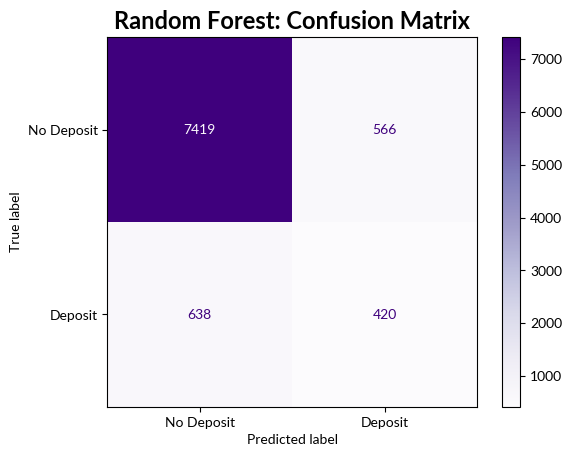

In [ ]:
# Матрица ошибок финальной модели Random Forest
cm_rf = confusion_matrix(y_test, y_test_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['No Deposit', 'Deposit']
).plot(cmap='Purples')

plt.title('Random Forest: Confusion Matrix', fontsize=17, fontweight='bold')
plt.show()

### *Анализ важности признаков*

In [ ]:
# Важность признаков Random Forest
feature_importance = pd.Series(
    rf_final.feature_importances_,
    index=X_train_encoded.columns
).sort_values(ascending=False)

feature_importance.head(10)

,0
poutcome_success,0.266020
age,0.128908
pdays,0.120266
balance,0.078188
housing_no,0.063675
previous,0.055989
housing_yes,0.053148
poutcome_failure,0.041841
poutcome_unknown,0.040856
poutcome_other,0.016668


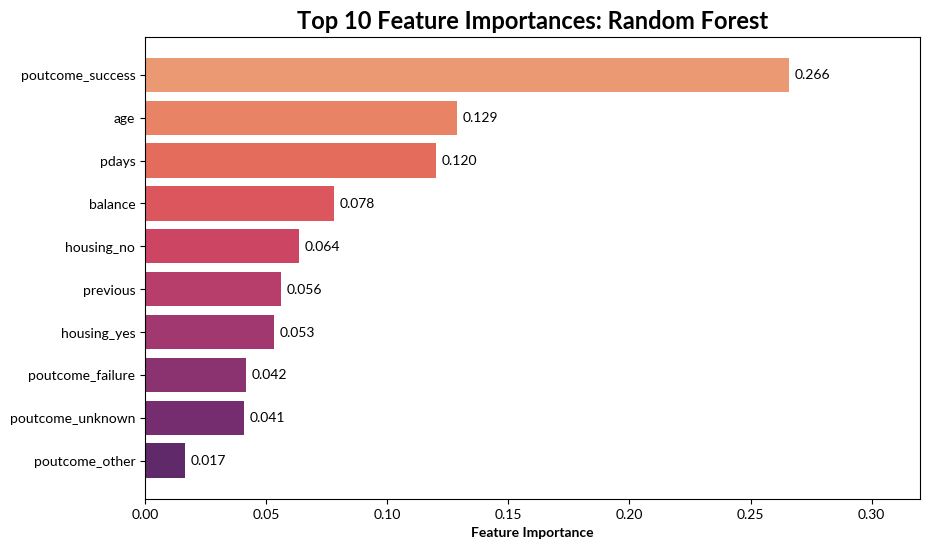

In [ ]:
# Диаграмма для десяти наиболее важных признаков
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_features.index,
    top_features.values,
    color=sns.color_palette('flare', 10)
)

plt.gca().invert_yaxis()

plt.title('Top 10 Feature Importances: Random Forest',
          fontsize=17, fontweight='bold')
plt.xlabel('Feature Importance', fontweight='bold')

plt.bar_label(bars, fmt='%.3f', padding=4)
plt.xlim(0, 0.32)

plt.show()

In [ ]:
# Важность признаков методом перемешивания
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_final,
    X_test_encoded,
    y_test,
    scoring='roc_auc',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.Series(
    perm_result.importances_mean,
    index=X_test_encoded.columns
).sort_values(ascending=False)

perm_importance.head(10)

,0
age,0.015198
balance,0.012520
pdays,0.012284
poutcome_success,0.010690
poutcome_unknown,0.007544
housing_yes,0.006125
marital_married,0.005345
previous,0.005150
poutcome_failure,0.004523
education_tertiary,0.004282


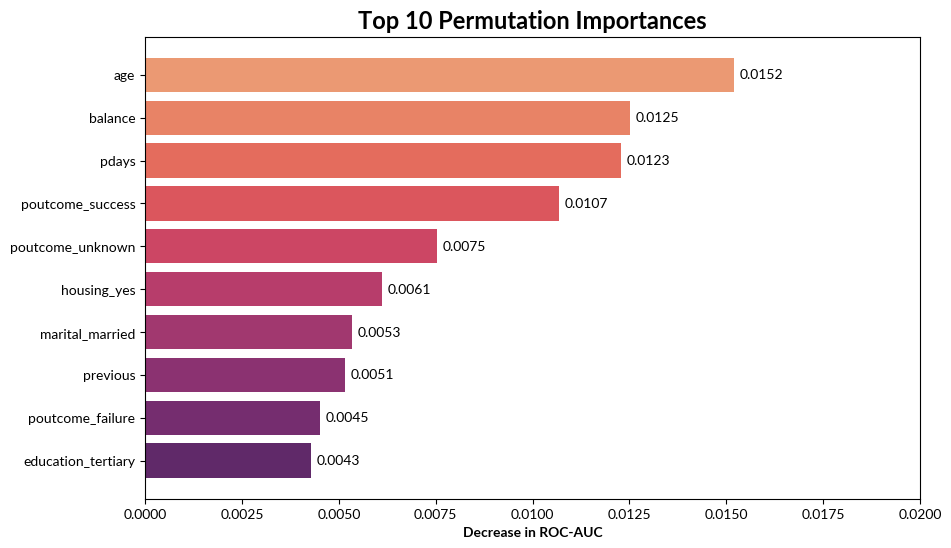

In [ ]:
# Диаграмма важности признаков методом перемешивания
top_perm = perm_importance.head(10)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_perm.index,
    top_perm.values,
    color=sns.color_palette('flare', 10)
)

plt.gca().invert_yaxis()

plt.title('Top 10 Permutation Importances', fontsize=17, fontweight='bold')
plt.xlabel('Decrease in ROC-AUC', fontweight='bold')

plt.bar_label(bars, fmt='%.4f', padding=4)
plt.xlim(0, 0.02)

plt.show()

In [ ]:
# Важность исходных признаков
baseline_auc = roc_auc_score(y_test, y_test_proba_rf)

rng = np.random.default_rng(42)
grouped_importance = {}

for feature in X_test.columns:
    scores = []

    for i in range(3):
        X_permuted = X_test.copy()
        X_permuted[feature] = rng.permutation(X_permuted[feature].values)

        X_permuted_encoded = pd.get_dummies(X_permuted, dtype=int)
        X_permuted_encoded = X_permuted_encoded.reindex(
            columns=X_train_encoded.columns,
            fill_value=0
        )

        probabilities = rf_final.predict_proba(X_permuted_encoded)[:, 1]
        scores.append(baseline_auc - roc_auc_score(y_test, probabilities))

    grouped_importance[feature] = np.mean(scores)

grouped_importance = pd.Series(grouped_importance).sort_values(ascending=False)

grouped_importance

,0
housing,0.038299
poutcome,0.028494
balance,0.016066
pdays,0.013244
marital,0.012931
age,0.012464
education,0.008546
loan,0.006731
job,0.006372
previous,0.005755


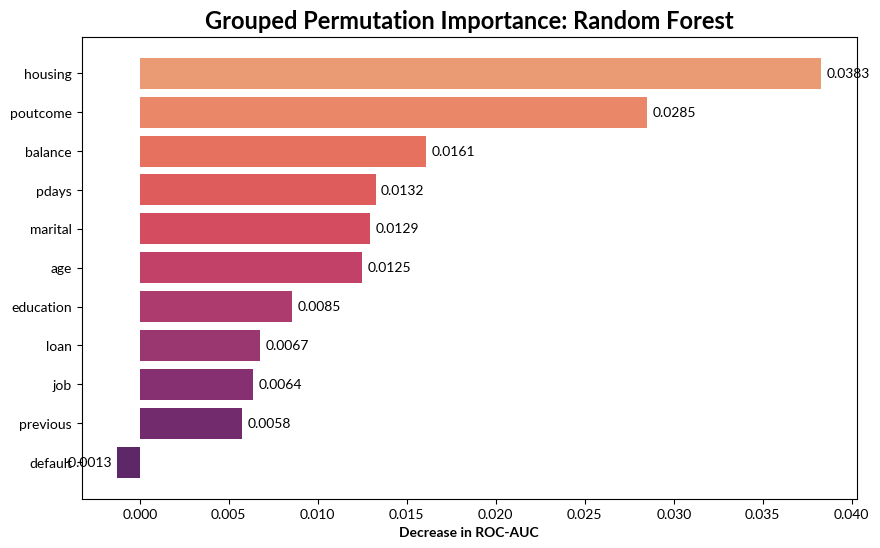

In [ ]:
# Диаграмма важности исходных признаков
plt.figure(figsize=(10, 6))

bars = plt.barh(
    grouped_importance.index,
    grouped_importance.values,
    color=sns.color_palette('flare', len(grouped_importance))
)

plt.gca().invert_yaxis()

plt.title('Grouped Permutation Importance: Random Forest',
          fontsize=17, fontweight='bold')
plt.xlabel('Decrease in ROC-AUC', fontweight='bold')

plt.bar_label(bars, fmt='%.4f', padding=4)

plt.show()

• По результатам сравнения моделей Random Forest продемонстрировал более высокое качество прогнозирования, чем логистическая регрессия. На тестовой выборке ROC-AUC случайного леса составил 0,7408, Average Precision — 0,3856. При выбранном на валидационной выборке пороге классификации 0,2 модель достигла Precision 42,6% и Recall 39,7%.

Анализ важности признаков показал, что наибольшую роль в прогнозировании играют наличие жилищного кредита, результат предыдущей маркетинговой кампании, баланс клиента и давность предыдущего контакта. Полученные результаты позволяют использовать модель для выделения групп клиентов с повышенной прогнозируемой вероятностью оформления банковского вклада.

## *Практические рекомендации по таргетированию клиентов*

In [ ]:
targeting_results = pd.DataFrame({
    'probability': y_test_proba_rf,
    'actual': y_test.to_numpy()
})

targeting_results = targeting_results.sort_values(
    'probability', ascending=False
)

targeting_results.head(10)

,probability,actual
3850,0.792200,1
6485,0.782978,1
6785,0.778026,1
2399,0.770383,1
1587,0.765898,1
348,0.759552,1
8493,0.759551,1
8158,0.754990,1
1533,0.753841,1
6460,0.752338,0


In [295]:
top_10 = targeting_results.head(round(len(targeting_results) * 0.1))

# Конверсия
overall_conversion = targeting_results['actual'].mean() * 100
top_10_conversion = top_10['actual'].mean() * 100

print(f'Общая конверсия: {overall_conversion:.2f}%')
print(f'Конверсия среди топ-10% клиентов: {top_10_conversion:.2f}%')
print(f'Прирост конверсии: {top_10_conversion - overall_conversion:.2f} п. п.')

Общая конверсия: 11.70%
Конверсия среди топ-10% клиентов: 44.36%
Прирост конверсии: 32.66 п. п.


In [297]:
# Lift для топ-10% клиентов
lift_10 = top_10_conversion / overall_conversion
print(f'Lift 10%: {lift_10:.2f}')

Lift 10%: 3.79


In [298]:
# Конверсия и Lift при разном охвате клиентов
lift_results = []

for share in [0.05, 0.10, 0.20, 0.30]:
    top_clients = targeting_results.head(round(len(targeting_results) * share))
    conversion = top_clients['actual'].mean() * 100
    lift = conversion / overall_conversion

    lift_results.append({
        'coverage': f'{share:.0%}',
        'conversion': round(conversion, 2),
        'lift': round(lift, 2)
    })

lift_results = pd.DataFrame(lift_results)
lift_results

,coverage,conversion,lift
0,5%,56.64,4.84
1,10%,44.36,3.79
2,20%,29.96,2.56
3,30%,23.96,2.05


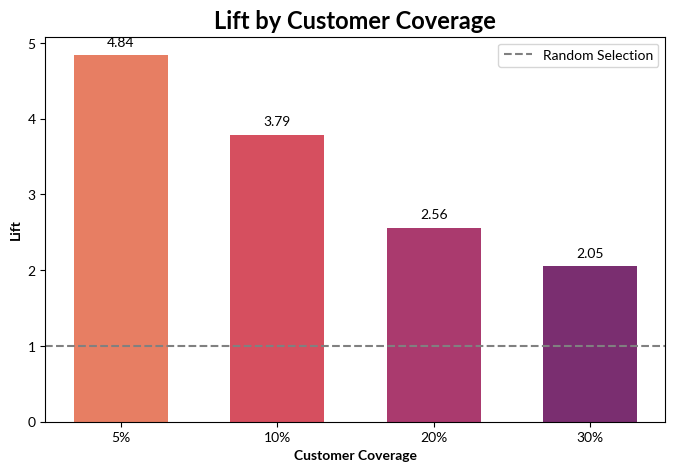

In [299]:
# Диаграмма Lift при разном охвате клиентов
plt.figure(figsize=(8, 5))

bars = plt.bar(
    lift_results['coverage'],
    lift_results['lift'],
    color=sns.color_palette('flare', 4),
    width=0.6
)

plt.axhline(1, color='gray', linestyle='--', label='Random Selection')

plt.title('Lift by Customer Coverage', fontsize=17, fontweight='bold')
plt.xlabel('Customer Coverage', fontweight='bold')
plt.ylabel('Lift', fontweight='bold')

plt.bar_label(bars, fmt='%.2f', padding=5)
plt.legend()

plt.show()

Результаты моделирования показывают, что Random Forest может использоваться для приоритизации клиентов при проведении маркетинговых кампаний. Наиболее высокая историческая конверсия наблюдается среди 5% клиентов с максимальными прогнозируемыми вероятностями оформления вклада (56,64%; Lift = 4,84). При увеличении охвата до 10% конверсия составляет 44,36% (Lift = 3,79), а до 30% — 23,96% (Lift = 2,05).

На основании полученных результатов банку можно рекомендовать использовать прогнозируемую вероятность оформления вклада для формирования приоритетных групп клиентов с учётом доступных ресурсов. При ограниченном бюджете целесообразно рассматривать более узкие сегменты с высокой прогнозируемой вероятностью отклика, а при необходимости расширения охвата - включать дополнительные группы клиентов.

При этом фактическую эффективность предложенного подхода необходимо проверить в условиях реальной маркетинговой кампании, поскольку результаты на исторических данных не гарантируют аналогичного эффекта в будущем.